# Causal attention and the key-value cache

During generation, a decoder can store keys and values for earlier tokens. The cached calculation should reproduce a full causal pass at every prefix.

The cache below belongs to one attention layer. Each step projects only the new token and then attends to the full prefix. A second test changes the suffix and checks the earlier outputs.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    for column in frame.columns:
        if "error" in column.lower() or column == "Change in query norm":
            frame[column] = frame[column].map(lambda value: f"{value:.2e}")
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)

## Compare the two decoding paths

Use a fresh prefix at every length. Count query-key dot products in one full-prefix recomputation per generation step and in incremental decoding.

In [2]:
rng = np.random.default_rng(23)
length, d = 32, 8
x = rng.normal(size=(length, d))
wq, wk, wv = rng.normal(scale=1 / np.sqrt(d), size=(3, d, d))


def full(seq):
    q, k, v = seq @ wq, seq @ wk, seq @ wv
    allow = np.tri(len(seq), dtype=bool)
    weights = softmax(np.where(allow, q @ k.T / np.sqrt(d), -np.inf))
    return weights @ v


reference = full(x)
cache_k, cache_v = [], []
errors = []
for i, token in enumerate(x):
    cache_k.append(token @ wk)
    cache_v.append(token @ wv)
    scores = (token @ wq) @ np.asarray(cache_k).T / np.sqrt(d)
    value = softmax(scores) @ np.asarray(cache_v)
    errors.append(np.max(np.abs(value - reference[i])))
perturbed = x.copy()
perturbed[12:] *= -3
assert np.allclose(full(perturbed)[:12], reference[:12]) and max(errors) < 1e-11
rows = []
for n in [4, 8, 16, 32]:
    rows.append(
        (
            n,
            sum(k * k for k in range(1, n + 1)),
            n * (n + 1) // 2,
            2 * n * d * x.itemsize,
            max(errors[:n]),
        )
    )
report(
    [
        "Tokens",
        "Full dense score entries",
        "Cached score entries",
        "Cache bytes",
        "Max abs error",
    ],
    rows,
)

,Tokens,Full dense score entries,Cached score entries,Cache bytes,Max abs error
0,4,30,10,512,5.55e-16
1,8,204,36,1024,5.55e-16
2,16,1496,136,2048,1.55e-15
3,32,11440,528,4096,1.55e-15


## Count the work as the prefix grows

The dense reference computes square score matrices before masking. The incremental path uses one query for each generation step.

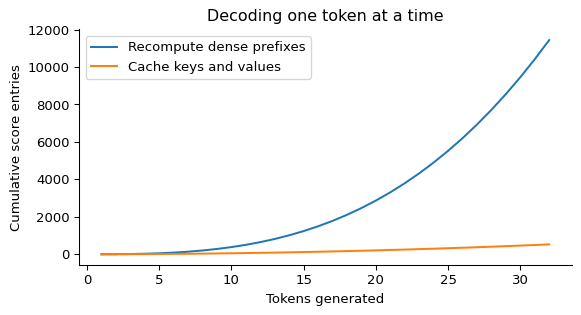

In [3]:
n = np.arange(1, length + 1)
fig, ax = plt.subplots(figsize=(6, 3.2), layout="constrained")
ax.plot(n, np.cumsum(n * n), label="Recompute dense prefixes")
ax.plot(n, np.cumsum(n), label="Cache keys and values")
ax.set(
    xlabel="Tokens generated",
    ylabel="Cumulative score entries",
    title="Decoding one token at a time",
)
ax.legend()
plt.show()

## Interpreting the result

The cache stores two vectors per token in this single-head example. The table counts score entries, independent of hardware speed or memory bandwidth.

## Exercise

Switch the causal mask off in the full pass and see which prefix-equivalence tests fail.

## References

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)

[Ainslie et al. (2023), GQA](https://arxiv.org/abs/2305.13245)